# DPO with lora for ASR corrections

## Install dependencies

In [ ]:
!pip install -q -U transformers datasets bitsandbytes  trl peft accelerate huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 141.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 65.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 925.0/925.0 kB 63.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 kB 63.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 63.8 MB/s eta 0:00:00


In [ ]:
# !nvidia-smi #check GPU access/availability

In [ ]:
# login to HF required to access certain models
from huggingface_hub import notebook_login


notebook_login()

## Import libraries

In [ ]:
import json
import os
import platform
import random
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, DatasetDict, load_dataset
from peft import LoraConfig, PeftConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    DataCollatorForSeq2Seq,
    set_seed,
)
from trl import DPOConfig, DPOTrainer


In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

# print("Python platform:", platform.platform())
# print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
# print("MPS available:", torch.backends.mps.is_available() if hasattr(torch.backends, "mps") else False)

CUDA available: True


## Load data

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
DATA_PATH = '/content/gdrive/My Drive/BiorampProjects/data/sample_data.jsonl'
raw_dataset = load_dataset(
    "json",
    data_files={"train": str(DATA_PATH)},
)["train"]

print(raw_dataset)
print("columns:", raw_dataset.column_names)
raw_dataset[0]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['id', 'session_id', 'source_model', 'domain', 'context', 'hypothesis', 'reference', 'errors', 'source_file', 'provenance', 'annotation_summary'],
    num_rows: 8
})
columns: ['id', 'session_id', 'source_model', 'domain', 'context', 'hypothesis', 'reference', 'errors', 'source_file', 'provenance', 'annotation_summary']


{'id': 'gemma3n::RES0199',
 'session_id': 'RES0199',
 'source_model': 'gemma3n',
 'domain': 'clinical_dialogue',
 'context': [{'speaker': 'unknown',
   'text': 'what brings you in hi i just came in today i have been having just been feeling really sick over the last three or four days it started with just like a headache and cough four days ago and then i started getting some nausea and vomiting few days back as well as diarrhea okay so the headache and cough started first you said right yeah okay let us talk about the headache first that came on four days ago has it been persistent or does it come and go it is been pretty persistent besides when i take some tylenol okay and does anything make it better or worse just a tylenol nothing really yeah it is pretty constant okay and have a an and sorry where exactly is it is it on it is like at the top of your head temples forehead it is kind of like my forehead in the top of my head on both sides okay and does it radiate your neck or anywhe

### Validate and inspect data

In [ ]:
REQUIRED_FIELDS = {"id", "session_id", "source_model", "domain", "hypothesis", "reference", "errors", "annotation_summary"}


def max_token_run(text):
    words = text.split()
    if not words:
        return 0, None
    best_count = current_count = 1
    best_word = current_word = words[0]
    for word in words[1:]:
        if word == current_word:
            current_count += 1
        else:
            current_word, current_count = word, 1
        if current_count > best_count:
            best_count, best_word = current_count, current_word
    return best_count, best_word


rows = []
invalid_indices = []
for index, record in enumerate(raw_dataset):
    missing = REQUIRED_FIELDS - set(record)
    if missing or not str(record.get("id", "")).strip() or not str(record.get("session_id", "")).strip() \
            or not str(record.get("hypothesis", "")).strip() or not str(record.get("reference", "")).strip():
        invalid_indices.append((index, sorted(missing)))
        continue
    max_run, repeated_word = max_token_run(record["hypothesis"])
    rows.append({
        "id": record["id"],
        "session_id": record["session_id"],
        "source_model": record["source_model"],
        "hyp_words": len(record["hypothesis"].split()),
        "ref_words": len(record["reference"].split()),
        "parsed_edits": record["annotation_summary"]["parsed_edits"],
        "annotated_edits": record["annotation_summary"]["annotated_edits"],
        "coverage": record["annotation_summary"]["coverage"],
        "max_severity": record["annotation_summary"]["max_rated_severity"],
        "max_repetition_run": max_run,
        "repeated_word": repeated_word,
    })

assert not invalid_indices, f"Invalid records: {invalid_indices}"
summary_df = pd.DataFrame(rows)
display(summary_df)
print("records:", len(summary_df))
print("unique sessions:", summary_df.session_id.nunique())
print("source models:", sorted(summary_df.source_model.unique()))
print("weighted annotation coverage:", summary_df.annotated_edits.sum() / summary_df.parsed_edits.sum())

pathological_ids = summary_df.loc[summary_df.max_repetition_run >= 20, "id"].tolist()
print("pathological repetition records:", pathological_ids)
print("These records remain visible for audit; DROP_PATHOLOGICAL controls whether they enter training.")

,id,session_id,source_model,hyp_words,ref_words,parsed_edits,annotated_edits,coverage,max_severity,max_repetition_run,repeated_word
0,gemma3n::RES0199,RES0199,gemma3n,1158,1143,87,13,0.149425,2,2,okay
1,gemma3n::day2_consultation06,day2_consultation06,gemma3n,1875,1934,198,7,0.035354,2,3,i
2,gemma3n::day3_consultation04,day3_consultation04,gemma3n,1089,1112,129,9,0.069767,2,2,hi
3,gemma3n::day5_consultation04,day5_consultation04,gemma3n,1486,1269,161,21,0.130435,3,220,chair
4,nemotron35::day1_consultation01,day1_consultation01,nemotron35,1274,1364,180,51,0.283333,2,12,but
5,phi4::46aacf84-fdd1-490b-a857-633d2e7763a0_7d4...,46aacf84-fdd1-490b-a857-633d2e7763a0_7d4de4c9d...,phi4,688,696,54,34,0.629630,3,2,you
6,qwen3::day4_consultation08,day4_consultation08,qwen3,1081,1692,88,10,0.113636,3,3,yeah
7,qwen3::day5_consultation02,day5_consultation02,qwen3,808,1092,36,9,0.250000,3,2,you


records: 8
unique sessions: 8
source models: ['gemma3n', 'nemotron35', 'phi4', 'qwen3']
weighted annotation coverage: 0.16505894962486603
pathological repetition records: ['gemma3n::day5_consultation04']
These records remain visible for audit; DROP_PATHOLOGICAL controls whether they enter training.


## Configure and Load Qwen3-0.6B

4-bit QLoRA is enabled only when CUDA is available.

In [ ]:
MODEL_NAME = "Qwen/Qwen3-0.6B"
USE_4BIT = torch.cuda.is_available()

if torch.cuda.is_available():
    COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    COMPUTE_DTYPE = torch.float16
else:
    COMPUTE_DTYPE = torch.float32

model_kwargs = {
    "trust_remote_code": True,
    "torch_dtype": COMPUTE_DTYPE,
    "device_map": "auto",
}

if USE_4BIT:
    model_kwargs["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=COMPUTE_DTYPE,
    )

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_kwargs)
tok_kwargs = {
    "padding_side": "right",
    "trust_remote_code": True,
}
tok_kwargs["model_max_length"] = 8192
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, **tok_kwargs)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Adjust maximum position embeddings to match our maximum sequence lengths
model.config.max_position_embeddings = 8192
model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False

print("model:", MODEL_NAME)
print("dtype:", COMPUTE_DTYPE)
print("4-bit QLoRA:", USE_4BIT)
print("model device:", next(model.parameters()).device)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

model: Qwen/Qwen3-0.6B
dtype: torch.bfloat16
4-bit QLoRA: True
model device: cuda:0


In [ ]:
model

Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 1024)
    (layers): ModuleList(
      (0-27): 28 x Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): Linear4bit(in_features=1024, out_features=2048, bias=False)
          (k_proj): Linear4bit(in_features=1024, out_features=1024, bias=False)
          (v_proj): Linear4bit(in_features=1024, out_features=1024, bias=False)
          (o_proj): Linear4bit(in_features=2048, out_features=1024, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
        )
        (mlp): Qwen3MLP(
          (gate_proj): Linear4bit(in_features=1024, out_features=3072, bias=False)
          (up_proj): Linear4bit(in_features=1024, out_features=3072, bias=False)
          (down_proj): Linear4bit(in_features=3072, out_features=1024, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen3RMSNorm((1024,), eps=1e-06)
 

## Inspect the Qwen Tokenizer and Chat Template

Qwen's built-in chat template and existing special tokens are used directly. No custom role tokens are added and model embeddings are not resized.

In [ ]:
print("special tokens:", tokenizer.all_special_tokens)
print("BOS:", tokenizer.bos_token, tokenizer.bos_token_id)
print("EOS:", tokenizer.eos_token, tokenizer.eos_token_id)
print("PAD:", tokenizer.pad_token, tokenizer.pad_token_id)
print("vocabulary size:", len(tokenizer))
print("model vocabulary size:", model.config.vocab_size)
# print("\nchat template preview:\n", tokenizer.chat_template[:1200], "...") #Uncomment to view chat_tempplate

special tokens: ['<|im_end|>', '<|endoftext|>', '<|im_start|>', '<|object_ref_start|>', '<|object_ref_end|>', '<|box_start|>', '<|box_end|>', '<|quad_start|>', '<|quad_end|>', '<|vision_start|>', '<|vision_end|>', '<|vision_pad|>', '<|image_pad|>', '<|video_pad|>']
BOS: None None
EOS: <|im_end|> 151645
PAD: <|endoftext|> 151643
vocabulary size: 151669
model vocabulary size: 151936


## Construct Chosen and Rejected Responses

For this pilot, `chosen` is the verified reference and `rejected` is the original hypothesis.

In [ ]:
SYSTEM_MESSAGE = (
    "You are a conservative clinical ASR correction system. "
    "Correct only recognition errors supported by the supplied transcript and safe dialogue context. "
    "Preserve clinically correct wording, especially negations, medication names, doses, measurements, "
    "anatomy, symptoms, and temporal expressions. Do not add facts that are absent from the input. "
    "Return only the corrected transcript, with no explanation."
)

# Configure training parameters
USE_CONTEXT = True
DROP_PATHOLOGICAL = True

def max_token_run(text):
    words = text.split()
    if not words:
        return 0, None
    best_count = current_count = 1
    best_word = current_word = words[0]
    for word in words[1:]:
        if word == current_word:
            current_count += 1
        else:
            current_word, current_count = word, 1
        if current_count > best_count:
            best_count, best_word = current_count, current_word
    return best_count, best_word

def rated_harm_mass(errors):
    return sum(2 ** (int(error["severity"]) - 1) for error in errors if error.get("severity") is not None)

def format_context(context):
    return "\n".join(f"{turn['speaker']}: {turn['text']}" for turn in context)

def build_preference(example):
    user_parts = [f"Domain: {example['domain']}"]
    if USE_CONTEXT:
        user_parts.append("Dialogue context:\n" + format_context(example.get("context", [])))
    user_parts.extend([
        "Current ASR hypothesis:\n" + example["hypothesis"],
        "Task: Return the corrected transcript only.",
    ])
    return {
        "prompt": [
            {"role": "system", "content": SYSTEM_MESSAGE},
            {"role": "user", "content": "\n\n".join(user_parts)},
        ],
        "chosen": [{"role": "assistant", "content": example["reference"]}],
        "rejected": [{"role": "assistant", "content": example["hypothesis"]}],
        "pair_source": "verified_reference_vs_source_hypothesis",
        "max_severity": example["annotation_summary"]["max_rated_severity"],
        "harm_gap": float(rated_harm_mass(example["errors"])),
        "annotation_coverage": float(example["annotation_summary"]["coverage"]),
    }

pathological_ids = []
for record in raw_dataset:
    run_length, repeated_word = max_token_run(record["hypothesis"])
    if run_length >= 20:
        pathological_ids.append(record["id"])

working_dataset = raw_dataset
if DROP_PATHOLOGICAL and pathological_ids:
    pathological_set = set(pathological_ids)
    working_dataset = working_dataset.filter(lambda row: row["id"] not in pathological_set)

preference_dataset = working_dataset.map(build_preference)
print("pathological IDs excluded:", pathological_ids if DROP_PATHOLOGICAL else [])
print("preference records:", len(preference_dataset), "of", len(raw_dataset))

# Safely display sample prompt, chosen and rejected contents
if len(preference_dataset) > 0:
    sample = preference_dataset[0]
    print("\n--- SAMPLE PROMPT (truncated) ---")
    print(sample["prompt"][1]["content"][:800] + "...\n")
    print("--- SAMPLE CHOSEN (truncated) ---")
    print(sample["chosen"][0]["content"][:500] + "...\n")
    print("--- SAMPLE REJECTED (truncated) ---")
    print(sample["rejected"][0]["content"][:500] + "...\n")


pathological IDs excluded: ['gemma3n::day5_consultation04']
preference records: 7 of 8

--- SAMPLE PROMPT (truncated) ---
Domain: clinical_dialogue

Dialogue context:
unknown: what brings you in hi i just came in today i have been having just been feeling really sick over the last three or four days it started with just like a headache and cough four days ago and then i started getting some nausea and vomiting few days back as well as diarrhea okay so the headache and cough started first you said right yeah okay let us talk about the headache first that came on four days ago has it been persistent or does it come and go it is been pretty persistent besides when i take some tylenol okay and does anything make it better or worse just a tylenol nothing really yeah it is pretty constant okay and have a an and sorry where exactly is it is it on it is like at the top of your head temples forehead it is kind of like...

--- SAMPLE CHOSEN (truncated) ---
what brings you in hi i just came in to



## Apply the Qwen Chat Template

Setting the training text to use the model's own template with `enable_thinking=False`. The reference appears only in the assistant segment. The prefix length is retained so prompt tokens can be masked from the loss.

In [ ]:
def render_preference(example):
    prompt_text = tokenizer.apply_chat_template(
        example["prompt"],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )
    chosen_text = tokenizer.apply_chat_template(
        example["prompt"] + example["chosen"],
        tokenize=False,
        add_generation_prompt=False,
        enable_thinking=False,
    )
    rejected_text = tokenizer.apply_chat_template(
        example["prompt"] + example["rejected"],
        tokenize=False,
        add_generation_prompt=False,
        enable_thinking=False,
    )
    assert chosen_text.startswith(prompt_text)
    assert rejected_text.startswith(prompt_text)
    assert chosen_text != rejected_text
    return {
        "prompt_text": prompt_text,
        "chosen_text": chosen_text,
        "rejected_text": rejected_text,
    }

rendered_dataset = preference_dataset.map(render_preference)
preview = rendered_dataset[0]
print("PROMPT:\n", preview["prompt_text"][:1600])
print("\nCHOSEN COMPLETION:\n", preview["chosen"][0]["content"][:1000])
print("\nREJECTED COMPLETION:\n", preview["rejected"][0]["content"][:1000])

Map:   0%|          | 0/7 [00:00<?, ? examples/s]

PROMPT:
 <|im_start|>system
You are a conservative clinical ASR correction system. Correct only recognition errors supported by the supplied transcript and safe dialogue context. Preserve clinically correct wording, especially negations, medication names, doses, measurements, anatomy, symptoms, and temporal expressions. Do not add facts that are absent from the input. Return only the corrected transcript, with no explanation.<|im_end|>
<|im_start|>user
Domain: clinical_dialogue

Dialogue context:
unknown: what brings you in hi i just came in today i have been having just been feeling really sick over the last three or four days it started with just like a headache and cough four days ago and then i started getting some nausea and vomiting few days back as well as diarrhea okay so the headache and cough started first you said right yeah okay let us talk about the headache first that came on four days ago has it been persistent or does it come and go it is been pretty persistent besides 

## Dataset Splits

This is just an example. We need a better data split. I will propose that the golden dataset used to establish the IRR be used as part of the test script

In [ ]:
session_ids = sorted(set(rendered_dataset["session_id"]))
rng = random.Random(SEED)
rng.shuffle(session_ids)

assert len(session_ids) >= 3, "Need at least three independent sessions for train/validation/test"
validation_sessions = set(session_ids[:1])
test_sessions = set(session_ids[1:2])
train_sessions = set(session_ids[2:])


def indices_for_sessions(dataset, allowed_sessions):
    return [i for i, session_id in enumerate(dataset["session_id"]) if session_id in allowed_sessions]


def to_trainer_dataset(split):
    # Standard explicit-prompt format preserves Qwen rendering with enable_thinking=False.
    return Dataset.from_dict({
        "prompt": split["prompt_text"],
        "chosen": [
            chosen_text[len(prompt_text):]
            for prompt_text, chosen_text in zip(split["prompt_text"], split["chosen_text"])
        ],
        "rejected": [
            rejected_text[len(prompt_text):]
            for prompt_text, rejected_text in zip(split["prompt_text"], split["rejected_text"])
        ],
    })


splits = DatasetDict({
    "train": rendered_dataset.select(indices_for_sessions(rendered_dataset, train_sessions)),
    "validation": rendered_dataset.select(indices_for_sessions(rendered_dataset, validation_sessions)),
    "test": rendered_dataset.select(indices_for_sessions(rendered_dataset, test_sessions)),
})

assert train_sessions.isdisjoint(validation_sessions)
assert train_sessions.isdisjoint(test_sessions)
assert validation_sessions.isdisjoint(test_sessions)
assert set(splits["train"]["session_id"]).isdisjoint(splits["validation"]["session_id"])
assert set(splits["train"]["session_id"]).isdisjoint(splits["test"]["session_id"])

trainer_splits = DatasetDict({name: to_trainer_dataset(split) for name, split in splits.items()})

split_summary = pd.DataFrame([
    {
        "split": name,
        "pairs": len(split),
        "sessions": len(set(split["session_id"])),
        "mean_harm_gap": float(np.mean(split["harm_gap"])) if len(split) else np.nan,
        "max_severity": max((value for value in split["max_severity"] if value is not None), default=None),
    }
    for name, split in splits.items()
])
display(split_summary)
print("train sessions:", sorted(train_sessions))
print("validation sessions:", sorted(validation_sessions))
print("test sessions:", sorted(test_sessions))

,split,pairs,sessions,mean_harm_gap,max_severity
0,train,5,5,32.8,3
1,validation,1,1,16.0,2
2,test,1,1,8.0,2


train sessions: ['46aacf84-fdd1-490b-a857-633d2e7763a0_7d4de4c9d3488a4bbd35634cbd3a2b66_l1RjPEwA', 'day1_consultation01', 'day3_consultation04', 'day4_consultation08', 'day5_consultation02']
validation sessions: ['RES0199']
test sessions: ['day2_consultation06']


## **Training**

### Configure LoRA Adapters

For this test, I am freezing all main modules, we can figure condifure which specific modules to freeze later

In [ ]:
if USE_4BIT:
    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650


## Configure the SFT Trainer


In [ ]:
MAX_PROMPT_LENGTH = 4096
MAX_COMPLETION_LENGTH = 4096
MAX_SEQUENCE_LENGTH = 8192

length_rows = []
violations = []
for split_name, split in splits.items():
    for example in split:
        assert [message["role"] for message in example["prompt"]] == ["system", "user"]
        assert [message["role"] for message in example["chosen"]] == ["assistant"]
        assert [message["role"] for message in example["rejected"]] == ["assistant"]
        assert example["chosen"][0]["content"].strip() != example["rejected"][0]["content"].strip()
        assert example["hypothesis"] in example["prompt"][1]["content"]
        if not USE_CONTEXT:
            assert "Dialogue context:" not in example["prompt"][1]["content"]

        prompt_ids = tokenizer(example["prompt_text"], add_special_tokens=False, truncation=False)["input_ids"]
        chosen_full_ids = tokenizer(example["chosen_text"], add_special_tokens=False, truncation=False)["input_ids"]
        rejected_full_ids = tokenizer(example["rejected_text"], add_special_tokens=False, truncation=False)["input_ids"]
        chosen_completion_tokens = len(chosen_full_ids) - len(prompt_ids)
        rejected_completion_tokens = len(rejected_full_ids) - len(prompt_ids)

        row = {
            "split": split_name,
            "id": example["id"],
            "prompt_tokens": len(prompt_ids),
            "chosen_completion_tokens": chosen_completion_tokens,
            "rejected_completion_tokens": rejected_completion_tokens,
            "chosen_total_tokens": len(chosen_full_ids),
            "rejected_total_tokens": len(rejected_full_ids),
        }
        length_rows.append(row)
        if (
            len(prompt_ids) > MAX_PROMPT_LENGTH
            or chosen_completion_tokens <= 0
            or rejected_completion_tokens <= 0
            or chosen_completion_tokens > MAX_COMPLETION_LENGTH
            or rejected_completion_tokens > MAX_COMPLETION_LENGTH
            or len(chosen_full_ids) > MAX_SEQUENCE_LENGTH
            or len(rejected_full_ids) > MAX_SEQUENCE_LENGTH
        ):
            violations.append(row)

assert not violations, (
    "Preference examples exceed configured limits. Create alignment-safe chunks or raise limits; "
    f"do not silently truncate: {violations}"
)
length_df = pd.DataFrame(length_rows)
display(length_df.sort_values(["chosen_total_tokens", "rejected_total_tokens"], ascending=False))
display(length_df.groupby("split").agg({
    "prompt_tokens": ["min", "median", "max"],
    "chosen_completion_tokens": ["min", "median", "max"],
    "rejected_completion_tokens": ["min", "median", "max"],
}))

representative = splits["train"][0]
print("ID:", representative["id"])
print("\nRendered prompt:\n", representative["prompt_text"][:2000])
print("\nChosen:\n", representative["chosen"][0]["content"][:1000])
print("\nRejected:\n", representative["rejected"][0]["content"][:1000])

,split,id,prompt_tokens,chosen_completion_tokens,rejected_completion_tokens,chosen_total_tokens,rejected_total_tokens
6,test,gemma3n::day2_consultation06,4045,2002,1935,6047,5980
3,train,qwen3::day4_consultation08,2953,1731,1114,4684,4067
1,train,nemotron35::day1_consultation01,2848,1423,1317,4271,4165
5,validation,gemma3n::RES0199,2506,1188,1210,3694,3716
0,train,gemma3n::day3_consultation04,2486,1200,1178,3686,3664
4,train,qwen3::day5_consultation02,2072,1133,831,3205,2903
2,train,phi4::46aacf84-fdd1-490b-a857-633d2e7763a0_7d4...,1994,737,713,2731,2707


prompt_tokens                ... rejected_completion_tokens              
                     min  median   max  ...                        min  median   max
split                                   ...                                         
test                4045  4045.0  4045  ...                       1935  1935.0  1935
train               1994  2486.0  2953  ...                        713  1114.0  1317
validation          2506  2506.0  2506  ...                       1210  1210.0  1210

[3 rows x 9 columns]

ID: gemma3n::day3_consultation04

Rendered prompt:
 <|im_start|>system
You are a conservative clinical ASR correction system. Correct only recognition errors supported by the supplied transcript and safe dialogue context. Preserve clinically correct wording, especially negations, medication names, doses, measurements, anatomy, symptoms, and temporal expressions. Do not add facts that are absent from the input. Return only the corrected transcript, with no explanation.<|im_end|>
<|im_start|>user
Domain: clinical_dialogue

Dialogue context:
unknown: hi hi hello i am doctor jacob and welcome to babylon hello hi so just before we start is it alright if you could confirm your name for me please hi there get to my name and your date of birth fourteenth november nineteen ninety six and your address for me please and twenty eight great road sw nineteen one ez that is correct and just to confirm that you are in a secure location and we can have a confidential conversation thank you okay so you 

In [ ]:
import inspect
from trl import DPOConfig, DPOTrainer

dpo_config_params = list(inspect.signature(DPOConfig).parameters.keys())
dpo_trainer_params = list(inspect.signature(DPOTrainer.__init__).parameters.keys())

print("DPOConfig 'length' parameters:", [p for p in dpo_config_params if 'length' in p or 'prompt' in p])
print("DPOTrainer 'length' parameters:", [p for p in dpo_trainer_params if 'length' in p or 'prompt' in p])


DPOConfig 'length' parameters: ['length_column_name', 'max_length']
DPOTrainer 'length' parameters: []


In [ ]:
from trl import DPOConfig, DPOTrainer

OUTPUT_DIR = Path("/content/gdrive/My Drive/BiorampProjects/DPO/outputs/qwen3-0.6b-clinical-asr-dpo")
BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
FP16 = torch.cuda.is_available() and not BF16

dpo_config = DPOConfig(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=1,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,
    max_length=MAX_SEQUENCE_LENGTH,
    learning_rate=5e-5,
    beta=0.1,  # DPO temperature parameter
    weight_decay=0.01,
    warmup_steps=5,
    lr_scheduler_type="cosine",
    logging_steps=1,
    eval_strategy="steps",
    eval_steps=1,
    save_strategy="steps",
    save_steps=1,
    save_total_limit=2,
    gradient_checkpointing=USE_4BIT,
    bf16=BF16,
    fp16=FP16,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    remove_unused_columns=False,
)

trainer = DPOTrainer(
    model=model,
    ref_model=None,  # PEFT handles the implicit reference model automatically
    args=dpo_config,
    train_dataset=trainer_splits["train"],
    eval_dataset=trainer_splits["validation"],
    processing_class=tokenizer,

)

batch = trainer.get_train_dataloader().dataset[0]
print("Keys in processed batch:", list(batch.keys()))


Adding EOS to train dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Keys in processed batch: ['prompt', 'chosen', 'rejected', 'prompt_ids', 'chosen_ids', 'rejected_ids']


In [ ]:
train_result = trainer.train()
train_result

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
1,0.693147,0.693147,0.035410,27655.000000,-3.587022,-3.542031,0.960471,0.000000,0.000000,0.000000,0.000000,-194.307312,-54.581036
2,0.693147,0.275032,0.035795,36093.000000,-3.564492,-3.517887,0.960471,1.166873,0.016671,1.000000,1.150203,-182.638580,-54.414330


TrainOutput(global_step=2, training_loss=0.6931471824645996, metrics={'train_runtime': 41.3077, 'train_samples_per_second': 0.121, 'train_steps_per_second': 0.048, 'total_flos': 102718146871296.0, 'train_loss': 0.6931471824645996, 'epoch': 1.0})

### Inspect the training

,loss,grad_norm,learning_rate,entropy,num_tokens,logits/chosen,logits/rejected,mean_token_accuracy,rewards/chosen,rewards/rejected,rewards/accuracies,rewards/margins,logps/chosen,logps/rejected,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,eval_entropy,eval_num_tokens,eval_logits/chosen,eval_logits/rejected,eval_mean_token_accuracy,eval_rewards/chosen,eval_rewards/rejected,eval_rewards/accuracies,eval_rewards/margins,eval_logps/chosen,eval_logps/rejected,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.693147,152.0,0.00000,0.034958,27655.0,-3.499143,-3.403248,0.96098,0.0,0.0,0.0,0.0,-230.573803,-38.458080,0.8,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.8,1,0.693147,2.3410,0.427,0.427,0.035410,27655.0,-3.587022,-3.542031,0.960471,0.000000,0.000000,0.0,0.000000,-194.307312,-54.581036,NaN,NaN,NaN,NaN,NaN
2,0.693147,282.0,0.00001,0.039101,36093.0,-3.583868,-3.333252,0.95927,0.0,0.0,0.0,0.0,-259.481689,-35.480537,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2,0.275032,2.3512,0.425,0.425,0.035795,36093.0,-3.564492,-3.517887,0.960471,1.166873,0.016671,1.0,1.150203,-182.638580,-54.414330,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41.3077,0.121,0.048,1.027181e+14,0.693147


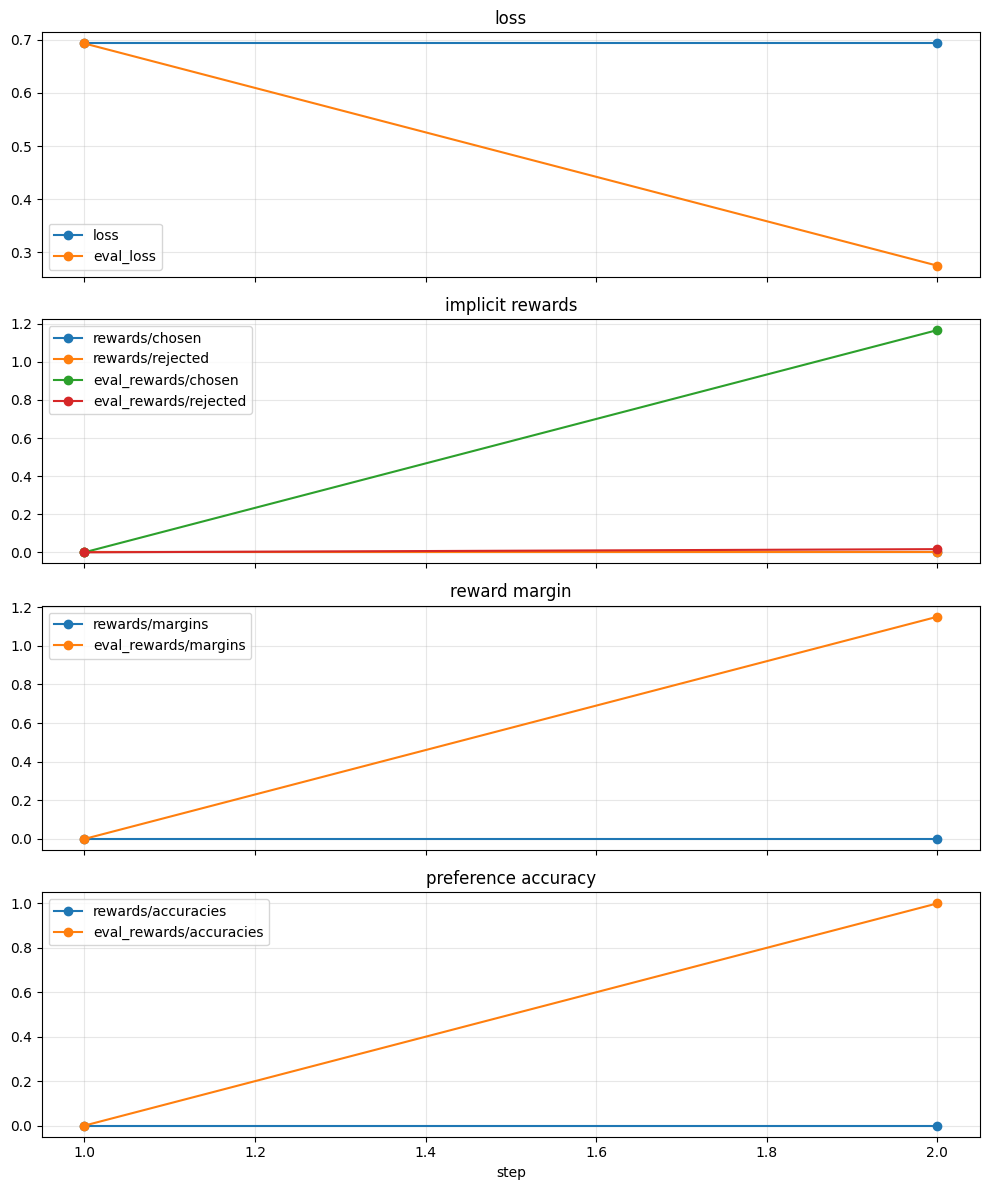

,value
train_runtime,4.130770e+01
train_samples_per_second,1.210000e-01
train_steps_per_second,4.800000e-02
total_flos,1.027181e+14
train_loss,6.931472e-01
epoch,1.000000e+00
best_checkpoint,NaN
global_step,2.000000e+00
cuda_peak_memory_GB,1.551602e+01


In [ ]:
history_df = pd.DataFrame(trainer.state.log_history)
if history_df.empty:
    print("No training metrics are available because training has not run.")
else:
    display(history_df)
    metric_groups = [
        ("loss", ["loss", "eval_loss"]),
        ("implicit rewards", ["rewards/chosen", "rewards/rejected", "eval_rewards/chosen", "eval_rewards/rejected"]),
        ("reward margin", ["rewards/margins", "eval_rewards/margins"]),
        ("preference accuracy", ["rewards/accuracies", "eval_rewards/accuracies"]),
    ]
    fig, axes = plt.subplots(len(metric_groups), 1, figsize=(10, 12), sharex=True)
    for axis, (title, candidates) in zip(axes, metric_groups):
        plotted = False
        for column in candidates:
            if column in history_df.columns:
                values = history_df.dropna(subset=[column])
                if not values.empty:
                    axis.plot(values["step"], values[column], marker="o", label=column)
                    plotted = True
        axis.set_title(title)
        axis.grid(alpha=0.3)
        if plotted:
            axis.legend()
    axes[-1].set_xlabel("step")
    plt.tight_layout()
    plt.show()

if train_result is not None:
    metrics = dict(train_result.metrics)
    metrics.update({
        "best_checkpoint": trainer.state.best_model_checkpoint,
        "global_step": trainer.state.global_step,
    })
    if torch.cuda.is_available():
        metrics["cuda_peak_memory_GB"] = torch.cuda.max_memory_allocated() / 1024**3

    display(pd.Series(metrics, name="value").to_frame())


### Test the model

In [ ]:
RUN_EVALUATION = True

evaluation_metrics = {}
generation_audit = {}

if RUN_EVALUATION:
    # Set Pandas to display all columns so chosen/rejected metrics aren't hidden
    pd.set_option('display.max_columns', None)

    evaluation_metrics["validation"] = trainer.evaluate(
        eval_dataset=trainer_splits["validation"],
        metric_key_prefix="validation",
    )
    evaluation_metrics["test"] = trainer.evaluate(
        eval_dataset=trainer_splits["test"],
        metric_key_prefix="test",
    )

    eval_df = pd.DataFrame(evaluation_metrics).T
    display(eval_df)

    held_out = splits["test"][0]
    prompt_text = held_out["prompt_text"]
    model_inputs = tokenizer(prompt_text, return_tensors="pt", add_special_tokens=False)
    model_device = next(trainer.model.parameters()).device
    model_inputs = {key: value.to(model_device) for key, value in model_inputs.items()}
    chosen_token_count = len(tokenizer(
        held_out["chosen"][0]["content"],
        add_special_tokens=False,
    )["input_ids"])
    max_new_tokens = min(MAX_COMPLETION_LENGTH, max(128, int(1.25 * chosen_token_count) + 32))

    trainer.model.eval()
    with torch.no_grad():
        generated_ids = trainer.model.generate(
            **model_inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            repetition_penalty=1.08,
            no_repeat_ngram_size=6,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    new_ids = generated_ids[0, model_inputs["input_ids"].shape[1]:]
    generated_correction = tokenizer.decode(new_ids, skip_special_tokens=True).strip()
    repetition_run, repeated_word = max_token_run(generated_correction)
    generation_audit = {
        "id": held_out["id"],
        "generated_words": len(generated_correction.split()),
        "chosen_words": len(held_out["chosen"][0]["content"].split()),
        "max_repetition_run": repetition_run,
        "repeated_word": repeated_word,
        "excessive_repetition": repetition_run >= 20,
    }

    print("\nID:", held_out["id"])
    print("\nSOURCE HYPOTHESIS / REJECTED:\n", held_out["hypothesis"])
    print("\nDPO GENERATED CORRECTION:\n", generated_correction)
    print("\nVERIFIED REFERENCE / CHOSEN (evaluation only):\n", held_out["reference"])
    print("\nGeneration audit:", generation_audit)
else:
    print("Evaluation skipped. It requires RUN_EVALUATION=True.")


Adding EOS to eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Training Loss,Validation Loss,Step,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
0.693147,0.275032,2,0.035795,36093.000000,-3.564492,-3.517887,0.960471,1.166873,0.016671,1.000000,1.150203,-182.638580,-54.414330


Adding EOS to eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Training Loss,Validation Loss,Step,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
0.693147,0.058460,2,0.033070,36093.000000,-3.453691,-3.241607,0.968048,2.723743,-0.086304,1.000000,2.810047,-330.273682,-47.586182


,validation_loss,eval_entropy,eval_num_tokens,eval_logits/chosen,eval_logits/rejected,eval_mean_token_accuracy,eval_rewards/chosen,eval_rewards/rejected,eval_rewards/accuracies,eval_rewards/margins,eval_logps/chosen,eval_logps/rejected,test_loss
validation,0.275032,0.035795,36093.0,-3.564492,-3.517887,0.960471,1.166873,0.016671,1.0,1.150203,-182.638580,-54.414330,NaN
test,NaN,0.033070,36093.0,-3.453691,-3.241607,0.968048,2.723743,-0.086304,1.0,2.810047,-330.273682,-47.586182,0.05846



ID: gemma3n::day2_consultation06

SOURCE HYPOTHESIS / REJECTED:
 hello hi there i am doctor demer from babylon good morning good morning good morning hi sorry before we start could i get your full name and date of birth is that possible yeah sure my name is gondo and i am twentyseven years old so i was born in one thousand nine hundred and ninetyone seventeenth of november that is perfect thank you for that are you john are you in a private place where you are okay to speak at the moment yeah okay perfect thank you for that okay so tell me what the problem is you have been having some difficulty breathing is that correct yeah exactly i have i am kind of struggling to breathe at the moment i i got stung by a wasp recently but i am not sure whether it is kind of bitten or stung but i i am feeling like slightly anxious that there is a bit of i have got a bit of a a rash on my arm where i got stung and i kind of yeah as i said i got it is difficult to breathing and potentially there is a 